## Load the preprocessed KDEF data

In [3]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open("data/kdef_preprocessed.pkl", "rb") as f:
    data = pickle.load(f)



In [4]:
X_train_images = data['X_train_kdef']
y_train = data["y_train_kdef"]
X_test_images = data["X_test_kdef"]
y_test = data["y_test_kdef"]

## Extract Facial Landmarks

Landmark shape: (68, 2)


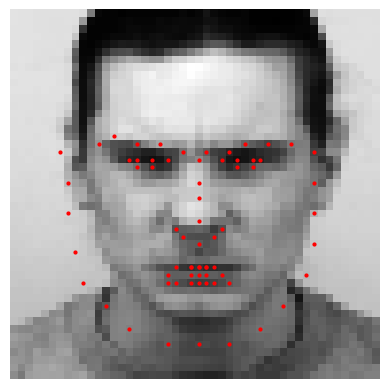

In [5]:
import dlib

shape_predict = dlib.shape_predictor("faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat")

image_shape = np.asarray(X_train_images[0]).copy()

# Convert floating-point pixels from [0, 1] to [0, 255] if required
if np.issubdtype(image_shape.dtype, np.floating) and image_shape.max() <= 1.0:
    image_shape = image_shape * 255

image_shape = np.clip(image_shape, 0, 255).astype(np.uint8)


image_bound = dlib.rectangle(0, 0, image_shape.shape[1]-1, image_shape.shape[0]-1)  
shape = shape_predict(image_shape, image_bound)
points = np.array([[p.x, p.y] for p in shape.parts()])

print("Landmark shape:", points.shape)

plt.imshow(image_shape, cmap="gray")
plt.scatter(points[:, 0], points[:, 1], c="red", s=4)
plt.axis("off")
plt.show()

We have used dlib's 68 point facial landmark to locate parts of the face like eyes, eyebrow, mouth, and nose. We will these landmark coordinate  for geometric features.

## Calculating Geomteric Features

 From the 68 facial landmarks, we will calaculate 7 meausurements: eye opening, mouth opening, mouth width, eyebrow-to-eye gap, smile curvature, eye-brow slant, eye-brow distance. For now we will inspect one image feature values before processing full dataset.

In [6]:
def geometric_facial_features(points):
    points = np.asarray(points, dtype=float)

    def distance(i, j):
        return float(np.linalg.norm(points[i] - points[j]))

    def safe_ratio(numerator, denominator):
        if not np.isfinite(denominator) or denominator <= 0:
            return np.nan
        return numerator / denominator

    face_width = distance(0, 16)
    inter_eye_dist = distance(36, 45)

    # Eye opening
    left_eye_width = distance(36, 39)
    right_eye_width = distance(42, 45)

    left_eye = safe_ratio(
        distance(37, 41) + distance(38, 40),
        2 * left_eye_width
    )
    right_eye = safe_ratio(
        distance(43, 47) + distance(44, 46),
        2 * right_eye_width
    )

    eye_opening = np.mean([left_eye, right_eye])

    # Mouth measurements
    inner_mouth_width_px = distance(60, 64)

    mouth_vertical_opening = np.mean([
        abs(points[61, 1] - points[67, 1]),
        abs(points[62, 1] - points[66, 1]),
        abs(points[63, 1] - points[65, 1])
    ])

    # Normalize width by face width
    inner_mouth_width = safe_ratio(
        inner_mouth_width_px, face_width
    )

    # Normalize opening by inner mouth width
    mouth_opening = safe_ratio(
        mouth_vertical_opening, inner_mouth_width_px
    )

    # Smile curvature
    smile_curvature = safe_ratio(
        np.mean(points[[48, 54], 1]) - points[51, 1],
        distance(48, 54)
    )

    # Eyebrow-to-eye gap
    eyebrow_gap = safe_ratio(
        np.mean(points[[19, 24], 1]) -
        np.mean(points[[37, 44], 1]),
        face_width
    )

    # Brow slant
    eyebrow_slant = safe_ratio(
        points[19, 1] - points[24, 1],
        distance(19, 24)
    )

    # Inner eyebrow distance
    inner_brow_distance = safe_ratio(
        distance(21, 22), inter_eye_dist
    )

    features_names = {
        "eye_opening": eye_opening,
        "mouth_opening": mouth_opening,
        "inner_mouth_width": inner_mouth_width,
        "eyebrow_gap": eyebrow_gap,
        "smile_curvature": smile_curvature,
        "brow_slant": eyebrow_slant,
        "inner_brow_distance": inner_brow_distance
    }

    return features_names



## Attach subject IDs to the KDEF data

In [7]:
from pathlib import Path
from matplotlib.pyplot import stem

emotion_labels = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}

results_dir = Path("data/KDEF_and_AKDEF/KDEF")

records = []

for img_path in results_dir.rglob("*.JPG"):
    img_name = img_path.stem
    subject = img_name[1:4]
    emo_code = img_name[4:6]
    emo_pose_code = img_name[6:8]

    if emo_pose_code == "S" and emo_code in emotion_labels:
        records.append({
            "path": str(img_path),
            "subject": subject,
            "emotion": emotion_labels[emo_code],})

frontal_df = pd.DataFrame(records)

with open("auxFiles/kdef_subject_split.pkl", "rb") as f:
    split_data = pickle.load(f)

trained_subjects = split_data["train_subjects"]
test_subjects = split_data["test_subjects"]

train_df = frontal_df[frontal_df["subject"].isin(trained_subjects)]
test_df = frontal_df[frontal_df["subject"].isin(test_subjects)]

with open("data/kdef_preprocessed.pkl", "rb") as f:
    data = pickle.load(f)

assert len(train_df) == len(data["X_train_kdef"])
assert len(test_df) == len(data["X_test_kdef"])
assert np.array_equal(train_df["emotion"].to_numpy(), data["y_train_kdef"])
assert np.array_equal(test_df["emotion"].to_numpy(), data["y_test_kdef"])

data["train_df"] = train_df["subject"].astype(str).to_numpy()
data["test_df"] = test_df["subject"].astype(str).to_numpy()

with open("data/kdef_preprocessed.pkl", "wb") as f:
    pickle.dump(data, f)

print("Saved sunject IDs")
print("Train subjects:", np.unique(data["train_df"]).size)
print("Test subjects:", np.unique(data["test_df"]).size)


Saved sunject IDs
Train subjects: 56
Test subjects: 14


## Create a subject-independent validation split

There are 56 training subjects into fuzzy training and validation groups. 

In [8]:
from sklearn.model_selection import train_test_split

train_df = np.asarray(data["train_df"], dtype=str)
test_df = np.asarray(data["test_df"]).tolist()

unique_subjects = np.unique(train_df)


fuzzy_trained_subjects, val_subjects = train_test_split(unique_subjects, test_size=0.2, random_state=42)

fuzzy_train_id = np.flatnonzero(np.isin(train_df, fuzzy_trained_subjects))
val_id = np.flatnonzero(np.isin(train_df, val_subjects))

X_fuzzy_train = X_train_images[fuzzy_train_id]
y_fuzzy_train = y_train[fuzzy_train_id]
X_val = X_train_images[val_id]  
y_val = y_train[val_id]

assert set(fuzzy_trained_subjects).isdisjoint(set(val_subjects))


print("Fuzzy train subjects:", np.unique(fuzzy_trained_subjects).size)
print("Validation subjects:", np.unique(val_subjects).size)
print("Fuzzy train samples:", len(X_fuzzy_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test_images))

Fuzzy train subjects: 44
Validation subjects: 12
Fuzzy train samples: 616
Validation samples: 168
Test samples: 196


## Extract features for training and validation images

In [9]:
# Define feature names BEFORE calling the extractor
feature_names = [
    "eye_opening",
    "mouth_opening",
    "inner_mouth_width",
    "eyebrow_gap",
    "smile_curvature",
    "brow_slant",
    "inner_brow_distance"
]

def extract_geometric_features(images):
    features_list = []
    for i, img in enumerate(images, start=1):

        img = np.asarray(img).copy()

        if np.issubdtype(img.dtype, np.floating) and img.max() <= 1.0:
            img = img * 255

        img_uint8 = np.clip(img, 0, 255).astype(np.uint8)
        img_bound = dlib.rectangle(0, 0, img_uint8.shape[1]-1, img_uint8.shape[0]-1)
        shape = shape_predict(img_uint8, img_bound)
        points = np.array([[p.x, p.y] for p in shape.parts()])
        features = geometric_facial_features(points)

        features_list.append([features[name] for name in feature_names])

        if i % 100 == 0 or i == len(images):
            print(f"Processed {i}/{len(images)} images")

    return np.asanyarray(features_list, dtype=float)


X_train_fuzzy = extract_geometric_features(X_fuzzy_train)
X_val_fuzzy = extract_geometric_features(X_val)

print("Fuzzy training features: ", X_train_fuzzy.shape)
print("Validation features: ", X_val_fuzzy.shape)
print("All values finite: ", np.isfinite(X_train_fuzzy).all() and np.isfinite(X_val_fuzzy).all())
print("Number of feature names:", len(feature_names))
print("Training matrix shape:", X_train_fuzzy.shape)

pd.DataFrame(X_train_fuzzy, columns=feature_names).head().round(3)

Processed 100/616 images
Processed 200/616 images
Processed 300/616 images
Processed 400/616 images
Processed 500/616 images
Processed 600/616 images
Processed 616/616 images
Processed 100/168 images
Processed 168/168 images
Fuzzy training features:  (616, 7)
Validation features:  (168, 7)
All values finite:  True
Number of feature names: 7
Training matrix shape: (616, 7)


,eye_opening,mouth_opening,inner_mouth_width,eyebrow_gap,smile_curvature,brow_slant,inner_brow_distance
0,0.200,0.143,0.212,-0.061,0.250,0.000,0.176
1,0.150,0.100,0.314,-0.078,0.125,-0.077,0.235
2,0.100,0.155,0.442,-0.118,-0.031,0.000,0.268
3,0.325,0.030,0.342,-0.124,0.192,-0.071,0.235
4,0.343,0.111,0.281,-0.141,0.091,0.000,0.316


## Set Fuzzy-term boundaries

We are using 25th, 50th, 75th percentiles of the fuzzy training data to define low, medium, and high ranges.

In [10]:
membership_thresholds = {}

for i, name in enumerate(feature_names):
    q25, q50, q75 = np.percentile(
        X_train_fuzzy[:, i],
        [25, 50, 75]
    )

    membership_thresholds[name] = {
        "q25": q25,
        "q50": q50,
        "q75": q75
    }

    print(
        f"{name:22s}: "
        f"q25={q25:.4f}, q50={q50:.4f}, q75={q75:.4f}"
    )

eye_opening           : q25=0.2391, q50=0.3311, q75=0.4077
mouth_opening         : q25=0.0458, q50=0.1250, q75=0.2481
inner_mouth_width     : q25=0.2489, q50=0.2769, q75=0.3145
eyebrow_gap           : q25=-0.1407, q50=-0.1129, q75=-0.0937
smile_curvature       : q25=0.0833, q50=0.1358, q75=0.2222
brow_slant            : q25=0.0000, q50=0.0000, q75=0.0624
inner_brow_distance   : q25=0.2349, q50=0.2774, q75=0.3083


## Convert Feature values to fuzzy memberships 

In [11]:
def fuzzify(feature_matrix):
    feature_matrix = np.asarray(feature_matrix, dtype=float)

    n_samples, n_features = feature_matrix.shape

    if n_features != len(feature_names):
        raise ValueError(
            f"Expected {len(feature_names)} features, "
            f"but received {n_features}."
        )

    memberships = np.zeros((n_samples, n_features, 3), dtype=float)

    for j, name in enumerate(feature_names):
        x = feature_matrix[:, j]

        if name == "brow_slant":
            # Negative = Low, near zero = Medium, positive = High
            low = np.clip(-x / 0.10, 0, 1)
            high = np.clip(x / 0.10, 0, 1)
            medium = 1 - np.maximum(low, high)

        else:
            #q25, q50, q75 = membership_thresholds[name]
            q25 = float(membership_thresholds[name]["q25"])
            q50 = float(membership_thresholds[name]["q50"])
            q75 = float(membership_thresholds[name]["q75"])

            # Low membership
            if q50 > q25:
                low = np.clip((q50 - x) / (q50 - q25), 0, 1)
            else:
                low = (x <= q50).astype(float)

            # High membership
            if q75 > q50:
                high = np.clip((x - q50) / (q75 - q50), 0, 1)
            else:
                high = (x > q50).astype(float)

            # Medium membership
            medium = 1 - np.maximum(low, high)

        memberships[:, j, :] = np.column_stack(
            (low, medium, high)
        )

    return memberships


# Use the extracted geometric features, NOT the 48x48 images
X_fuzzy_train = X_train_fuzzy
X_fuzzy_val = X_val_fuzzy

# Calculate memberships
train_memberships = fuzzify(X_fuzzy_train)
val_memberships = fuzzify(X_fuzzy_val)

print("Training memberships:", train_memberships.shape)
print("Validation memberships:", val_memberships.shape)

print(
    "Largest deviation from sum 1:",
    np.max(
        np.abs(train_memberships.sum(axis=2) - 1)
    ).round(6)

)

terms = ["Low", "Medium", "High"]

display(
    pd.DataFrame(
        train_memberships[0],
        index=feature_names,
        columns=terms
    ).round(3)
)

Training memberships: (616, 7, 3)
Validation memberships: (168, 7, 3)
Largest deviation from sum 1: 0.0


,Low,Medium,High
eye_opening,1.0,0.000,0.000
mouth_opening,0.0,0.855,0.145
inner_mouth_width,1.0,0.000,0.000
eyebrow_gap,0.0,0.000,1.000
smile_curvature,0.0,0.000,1.000
brow_slant,-0.0,1.000,0.000
inner_brow_distance,1.0,0.000,0.000


## Learn fuzzy emotion rules



In [12]:
from itertools import product

emotion_names = sorted(str(label) for label in np.unique(y_fuzzy_train))
emotion_to_index = {
    emotion: i for i, emotion in enumerate(emotion_names)
}

candidate_counts = {}

for i, label in enumerate(y_fuzzy_train):
    label_index = emotion_to_index[str(label)]

    for terms in product(range(3), repeat=len(feature_names)):
        strength = min(
            train_memberships[i, feature_index, term]
            for feature_index, term in enumerate(terms)
        )

        if strength == 0:
            continue

        if terms not in candidate_counts:
            candidate_counts[terms] = np.zeros(len(emotion_names))

        candidate_counts[terms][label_index] += strength


minimum_support = 1.0
rules = []

for terms, class_counts in candidate_counts.items():
    support = class_counts.sum()

    if support < minimum_support:
        continue

    prediction_index = int(np.argmax(class_counts))
    probabilities = (class_counts + 1) / (support + len(emotion_names))

    conditions = " AND ".join(
        f"{name} is {terms[term]}"
        for name, term in zip(feature_names, terms)
    )

    rules.append({
        "terms": terms,
        "prediction": emotion_names[prediction_index],
        "support": support,
        "confidence": class_counts[prediction_index] / support,
        "probabilities": probabilities,
        "rule": (
            f"IF {conditions} THEN emotion is "
            f"{emotion_names[prediction_index]}"
        ),
    })

rules_df = pd.DataFrame(rules).sort_values(
    ["support", "confidence"], ascending=False
)

print("Number of learned rules:", len(rules_df))
rules_df[["rule", "support", "confidence"]].head(10).round(3)

Number of learned rules: 624


,rule,support,confidence
113,IF eye_opening is 0 AND mouth_opening is 0 AND...,16.639,0.831
114,IF eye_opening is 1 AND mouth_opening is 1 AND...,12.509,0.786
150,IF eye_opening is 0 AND mouth_opening is 1 AND...,8.639,0.544
226,IF eye_opening is 0 AND mouth_opening is 0 AND...,8.336,0.352
454,IF eye_opening is 0 AND mouth_opening is 2 AND...,7.979,0.909
6,IF eye_opening is 0 AND mouth_opening is 0 AND...,7.918,0.487
198,IF eye_opening is 0 AND mouth_opening is 0 AND...,7.629,0.650
306,IF eye_opening is 0 AND mouth_opening is 0 AND...,7.591,0.319
228,IF eye_opening is 0 AND mouth_opening is 0 AND...,7.192,0.452
240,IF eye_opening is 0 AND mouth_opening is 0 AND...,6.915,0.329


## Predict and evaluate on validation data


In [13]:

from matplotlib import cm
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix
)

def predict_fuzzy(rules, memberships, classes):
    predictions = []

    for sample in memberships:
        class_scores = {label: 0.0 for label in classes}
        for rule in rules:
            terms = rule["terms"]
            # Minimum membership across all seven conditions
            strength = np.min(sample[np.arange(sample.shape[0]), terms])
            if strength <= 0:
                continue
            # Weight each rule by its confidence
            class_scores[rule["prediction"]] += (strength * rule["confidence"])

        if max(class_scores.values()) == 0:
            predictions.append(None)
        else:
            predictions.append(max(class_scores, key=class_scores.get))

    return np.asarray(predictions, dtype=object)


classes = np.unique(y_fuzzy_train)

y_val_pred = predict_fuzzy(
    rules,
    val_memberships,
    classes
)

y_val_array = np.asarray(y_val)
valid = np.array([pred is not None for pred in y_val_pred])

if valid.any():
    print("\nValidation accuracy:",round(accuracy_score(y_val_array[valid], y_val_pred[valid]),4))
    print("\nClassification report:")
    print(classification_report(y_val_array[valid],y_val_pred[valid],labels=classes,zero_division=0))


Validation accuracy: 0.4085

Classification report:
              precision    recall  f1-score   support

      afraid       0.36      0.21      0.26        24
       angry       0.52      0.50      0.51        24
     disgust       0.12      0.10      0.11        21
       happy       0.58      0.78      0.67        23
     neutral       0.24      0.29      0.26        24
         sad       0.26      0.21      0.23        24
    surprise       0.58      0.75      0.65        24

    accuracy                           0.41       164
   macro avg       0.38      0.41      0.39       164
weighted avg       0.38      0.41      0.39       164



## Confusion Matrix

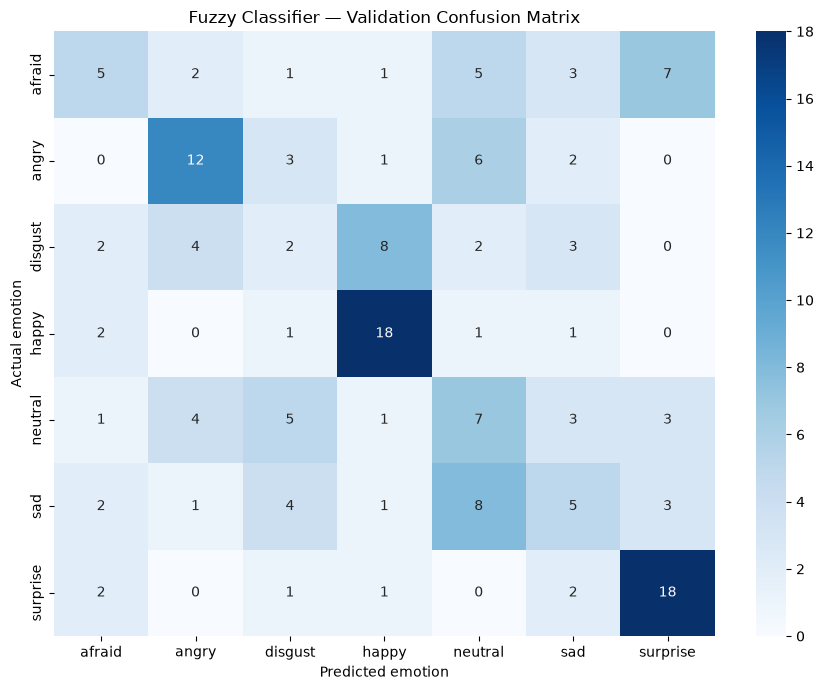

In [14]:

emotion_labels = [
    "afraid", "angry", "disgust", "happy",
    "neutral", "sad", "surprise"
]

cm = confusion_matrix(
    y_val_array[valid],
    y_val_pred[valid],
    labels=emotion_labels
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotion_labels,
    yticklabels=emotion_labels
)

plt.xlabel("Predicted emotion")
plt.ylabel("Actual emotion")
plt.title("Fuzzy Classifier — Validation Confusion Matrix")
plt.tight_layout()
plt.show()


## Final evaluation on held-out KDEF test subjects

The fuzzy classifier was evaluated using accuracy,balanced accuracy, and macro F1-acore. Also confusion is generated to visualise predictions across the seven emotions.

Processed 100/196 images
Processed 196/196 images
Test Accuracy:          0.4309
Test Balanced Accuracy: 0.4318
Test Macro F1-score:    0.4102


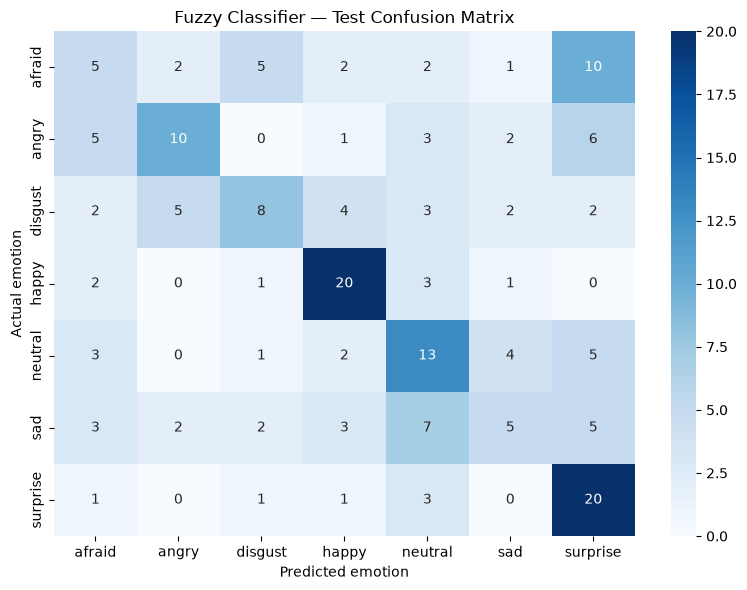

In [15]:
from sklearn.metrics import balanced_accuracy_score

# Extract geometric features for the held-out test set
X_test_fuzzy = extract_geometric_features(X_test_images)

# Convert features to fuzzy memberships
test_memberships = fuzzify(X_test_fuzzy)

# Predict emotions
y_test_pred = predict_fuzzy(
    rules,
    test_memberships,
    classes
)

y_test_array = np.asarray(y_test)

# Exclude samples without a prediction
valid_test = np.array([
    pred is not None for pred in y_test_pred
])

y_true_valid = y_test_array[valid_test]
y_pred_valid = y_test_pred[valid_test]

# Calculate metrics on samples with predictions
test_accuracy = accuracy_score(
    y_true_valid, y_pred_valid
)

test_balanced_accuracy = balanced_accuracy_score(
    y_true_valid, y_pred_valid
)

test_macro_f1 = f1_score(
    y_true_valid,
    y_pred_valid,
    labels=classes,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy:          {test_accuracy:.4f}")
print(f"Test Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"Test Macro F1-score:    {test_macro_f1:.4f}")

# Plot confusion matrix
cm = confusion_matrix(
    y_true_valid,
    y_pred_valid,
    labels=classes
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted emotion")
plt.ylabel("Actual emotion")
plt.title("Fuzzy Classifier — Test Confusion Matrix")
plt.tight_layout()
plt.show()


The held-out test subjects were used only for this final evaluation.

- **Accuracy:** 43.09%
- **Balanced accuracy:** 43.18%
- **Macro F1:** 41.02%